1. Import Library

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('default')

2. Hubungkan Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


3. Load Dataset Hasil Analisis

In [ ]:
file_path = '/content/drive/MyDrive/BIG DATA/dataset_setelah_pra_processing.csv'

df = pd.read_csv(file_path, sep=';')

print("Dataset berhasil dibaca")
display(df.head())

Dataset berhasil dibaca


,Judul,Isi,Tanggal,Link,Sumber,Sentimen,text,Topik_Cluster,Topik
0,"SBY Hadiri Halalbihalal di Istana, Disambut La...",sby hadiri halalbihalal di istana disambut lan...,"Kompas.com, 21 Maret 2026, 16:10 WIB",https://nasional.kompas.com/read/2026/03/21/16...,Kompas,Netral,"SBY Hadiri Halalbihalal di Istana, Disambut La...",2,Nasional
1,"Suasana Hangat Halalbihalal di Istana, Warga h...",suasana hangat halalbihalal di istana warga hi...,"Kompas.com, 22 Maret 2026, 10:47 WIB",https://nasional.kompas.com/read/2026/03/22/10...,Kompas,Netral,"Suasana Hangat Halalbihalal di Istana, Warga h...",0,Politik
2,KPK Alihkan Eks Menag Yaqut ke Tahanan Rumah S...,kpk alihkan eks menag yaqut ke tahanan rumah s...,"Kompas.com, 22 Maret 2026, 10:06 WIB",https://nasional.kompas.com/read/2026/03/22/10...,Kompas,Netral,KPK Alihkan Eks Menag Yaqut ke Tahanan Rumah S...,1,Kriminal
3,"Momen Kebersamaan Prabowo, Titiek, dan Didit S...",momen kebersamaan prabowo titiek dan didit saa...,"Kompas.com, 22 Maret 2026, 09:17 WIB",https://nasional.kompas.com/read/2026/03/22/09...,Kompas,Netral,"Momen Kebersamaan Prabowo, Titiek, dan Didit S...",0,Politik
4,Momen Hangat Prabowo Sambut Jokowi di Istana: ...,momen hangat prabowo sambut jokowi di istana m...,"Kompas.com, 22 Maret 2026, 08:06 WIB",https://nasional.kompas.com/read/2026/03/22/08...,Kompas,Netral,Momen Hangat Prabowo Sambut Jokowi di Istana: ...,2,Nasional


 4. Informasi Dataset

In [ ]:
print("Jumlah Baris dan Kolom:")
print(df.shape)

print("\nInformasi Dataset:")
df.info()

print("\nMissing Value:")
print(df.isnull().sum())

Jumlah Baris dan Kolom:
(67263, 9)

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67263 entries, 0 to 67262
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Judul          67263 non-null  object
 1   Isi            67263 non-null  object
 2   Tanggal        67263 non-null  object
 3   Link           67263 non-null  object
 4   Sumber         67263 non-null  object
 5   Sentimen       67263 non-null  object
 6   text           67263 non-null  object
 7   Topik_Cluster  67263 non-null  int64 
 8   Topik          67263 non-null  object
dtypes: int64(1), object(8)
memory usage: 4.6+ MB

Missing Value:
Judul            0
Isi              0
Tanggal          0
Link             0
Sumber           0
Sentimen         0
text             0
Topik_Cluster    0
Topik            0
dtype: int64


5. Distribusi Sentimen (Bar Chart)

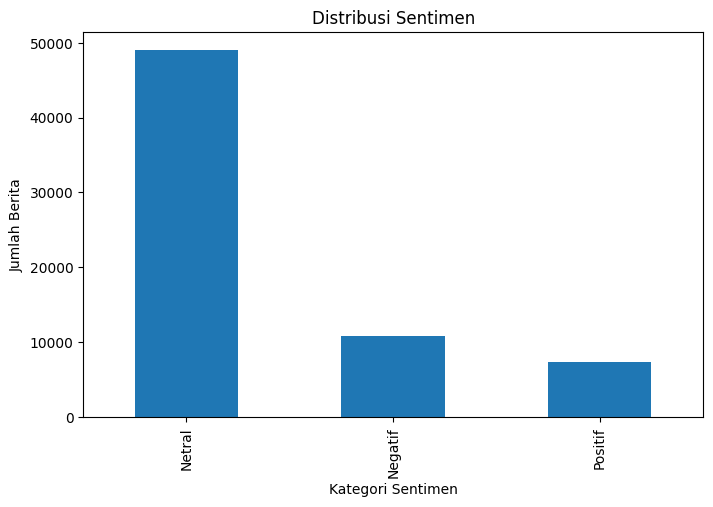

In [ ]:
plt.figure(figsize=(8,5))

df['Sentimen'].value_counts().plot(
    kind='bar'
)

plt.title('Distribusi Sentimen')
plt.xlabel('Kategori Sentimen')
plt.ylabel('Jumlah Berita')

plt.show()

6. Distribusi Topik (Bar Chart)

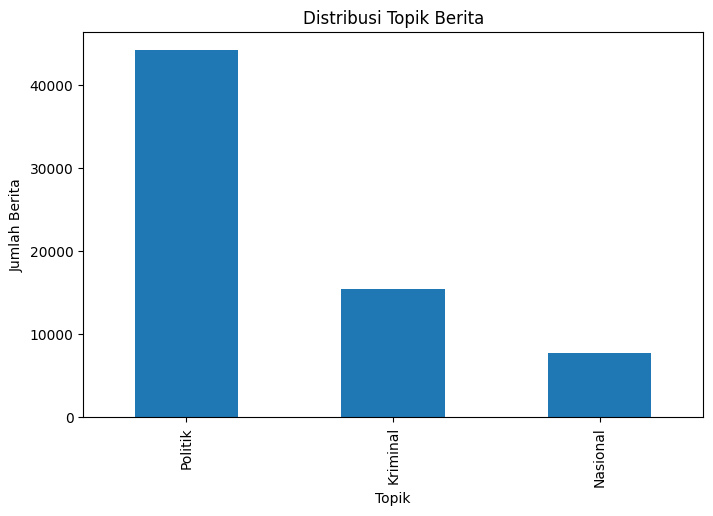

In [ ]:
plt.figure(figsize=(8,5))

df['Topik'].value_counts().plot(
    kind='bar'
)

plt.title('Distribusi Topik Berita')
plt.xlabel('Topik')
plt.ylabel('Jumlah Berita')

plt.show()

7. Pie Chart Sentimen

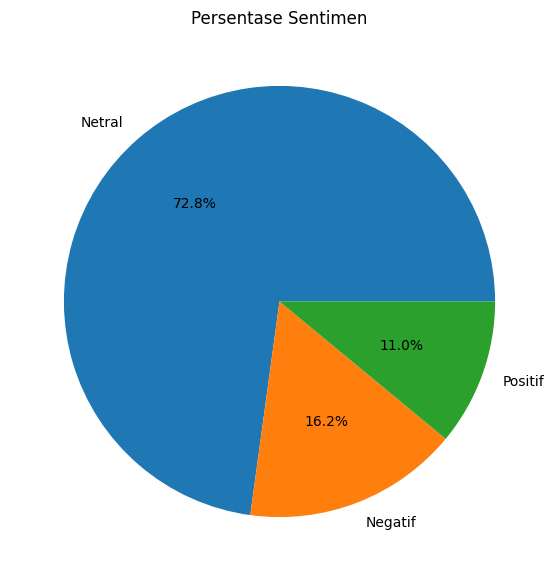

In [ ]:
plt.figure(figsize=(7,7))

df['Sentimen'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Persentase Sentimen')
plt.ylabel('')

plt.show()

8. Heatmap Sentimen vs Topik

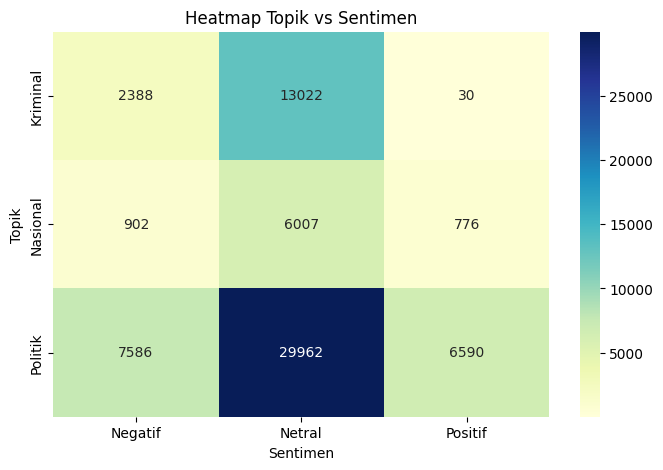

In [ ]:
ct = pd.crosstab(
    df['Topik'],
    df['Sentimen']
)

plt.figure(figsize=(8,5))

sns.heatmap(
    ct,
    annot=True,
    cmap='YlGnBu',
    fmt='d'
)

plt.title('Heatmap Topik vs Sentimen')

plt.show()

9. Stacked Bar Chart

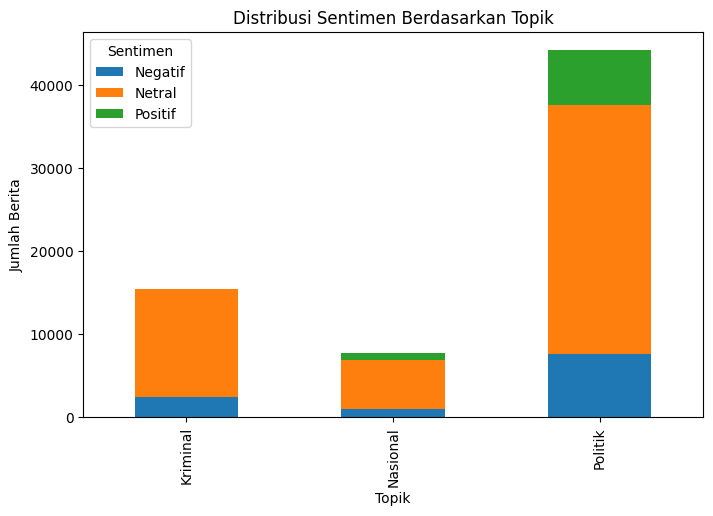

In [ ]:
ct = pd.crosstab(
    df['Topik'],
    df['Sentimen']
)

ct.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5)
)

plt.title('Distribusi Sentimen Berdasarkan Topik')
plt.xlabel('Topik')
plt.ylabel('Jumlah Berita')

plt.show()

10. Count Plot Sentimen per Topik

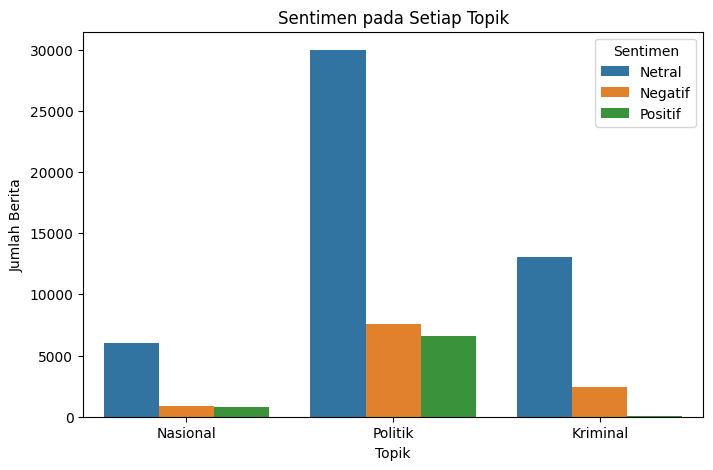

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Topik',
    hue='Sentimen'
)

plt.title('Sentimen pada Setiap Topik')
plt.xlabel('Topik')
plt.ylabel('Jumlah Berita')

plt.show()

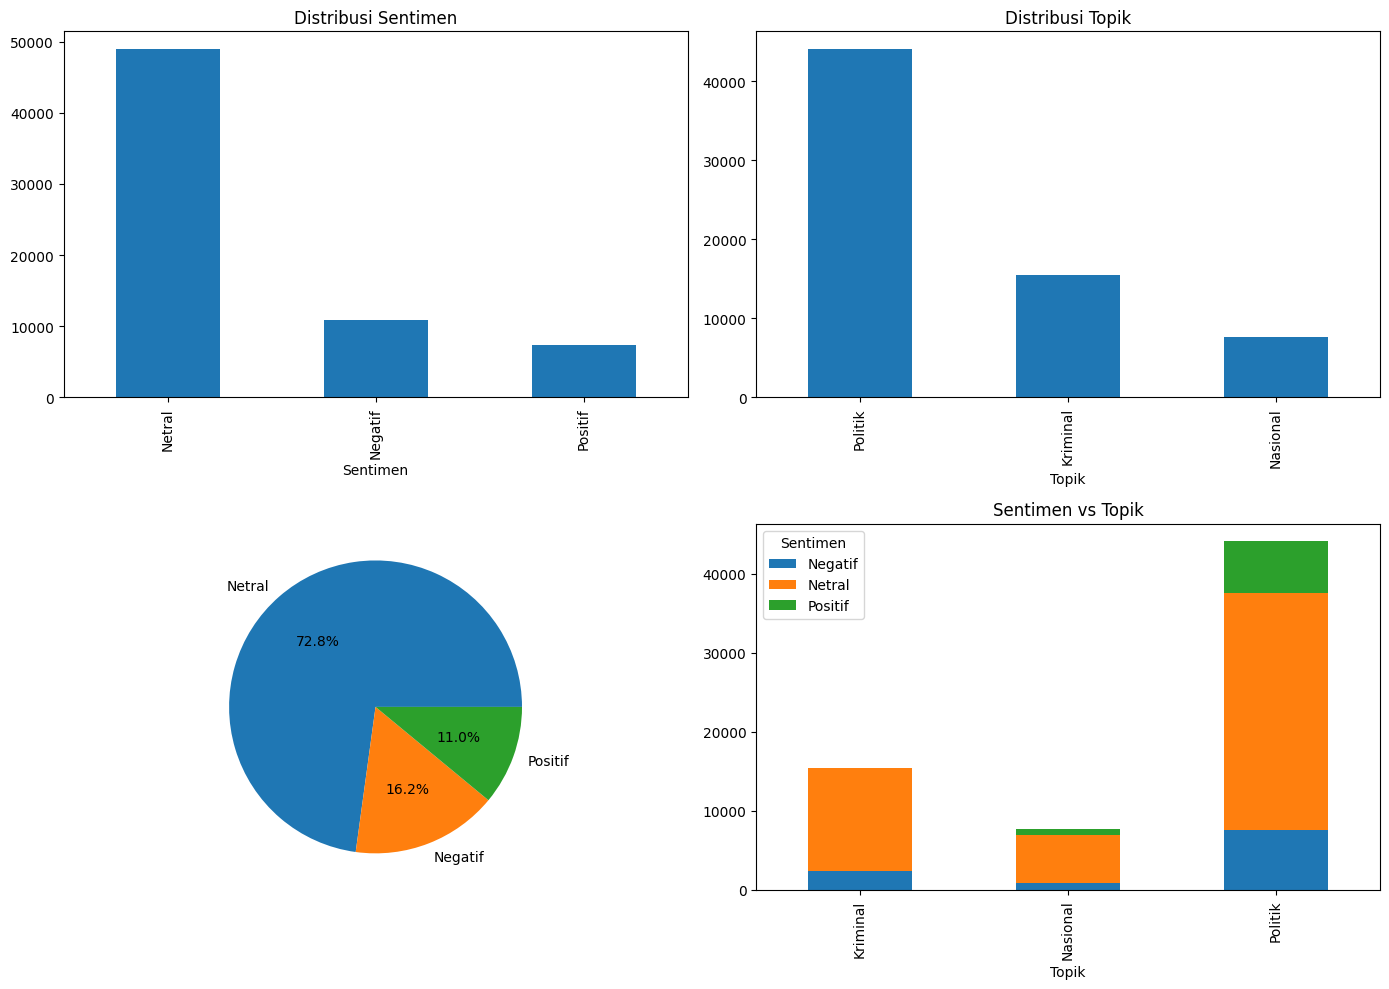

In [ ]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14,10)
)

# Grafik 1
df['Sentimen'].value_counts().plot(
    kind='bar',
    ax=axes[0,0]
)
axes[0,0].set_title('Distribusi Sentimen')

# Grafik 2
df['Topik'].value_counts().plot(
    kind='bar',
    ax=axes[0,1]
)
axes[0,1].set_title('Distribusi Topik')

# Grafik 3
df['Sentimen'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[1,0]
)
axes[1,0].set_ylabel('')

# Grafik 4
ct.plot(
    kind='bar',
    stacked=True,
    ax=axes[1,1]
)
axes[1,1].set_title('Sentimen vs Topik')

plt.tight_layout()

plt.show()